What I want to do:
- Import all relevant packages
- Fetch data
- Split data into test and training
- Normalize (scale) data
- Reduce the number of dimensions
- plot the data

- Supervised method

- Unsupervised method

# Dry Bean
## Imported packages

In [ ]:
import pandas as pd

from ucimlrepo import fetch_ucirepo
# ucimlrepo is a package that downloads datasets directly from UCI, so you don't have to download files yourself


from sklearn.model_selection import train_test_split    # For the train and test split part
from sklearn.preprocessing import StandardScaler        # For the part with scaling of measurements

import matplotlib.pyplot as plt         # For the 2D plot part
from sklearn.decomposition import PCA   # For the 2D plot part

import numpy as np      # For K-mean
import math
import random

## Prepare Data
[UCI page](https://archive.ics.uci.edu/dataset/602/dry+bean+dataset)

In [5]:
# fetch dataset 
dry_bean = fetch_ucirepo(id=602) 
  
# data (as pandas dataframes) 
X = dry_bean.data.features 
y = dry_bean.data.targets 
  
# metadata 
print(dry_bean.metadata) 
  
# variable information 
print(dry_bean.variables) 

X.head()

{'uci_id': 602, 'name': 'Dry Bean', 'repository_url': 'https://archive.ics.uci.edu/dataset/602/dry+bean+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/602/data.csv', 'abstract': 'Images of 13,611 grains of 7 different registered dry beans were taken with a high-resolution camera. A total of 16 features; 12 dimensions and 4 shape forms, were obtained from the grains.', 'area': 'Biology', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 13611, 'num_features': 16, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': ['Class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2020, 'last_updated': 'Thu Mar 28 2024', 'dataset_doi': '10.24432/C50S4B', 'creators': [], 'intro_paper': {'ID': 244, 'type': 'NATIVE', 'title': 'Multiclass classification of dry beans using computer vision and machine learning techniques', 'authors': 'M. Koklu, Ilker Ali Özkan', 'venue': 'Co

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166


## Splitt Data

In [6]:
y = y["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # 20 % til test, 80 % til trening.
    stratify=y,          # samme fordeling av bønner i begge deler.
    random_state=42     # 42 er bare et tilfeldig tall (meningen med livet...)     Gir samme oppdeling hver gang du kjører.
)

print(X_train.shape, X_test.shape)

(10888, 16) (2723, 16)


Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64
Manglende verdier: 0


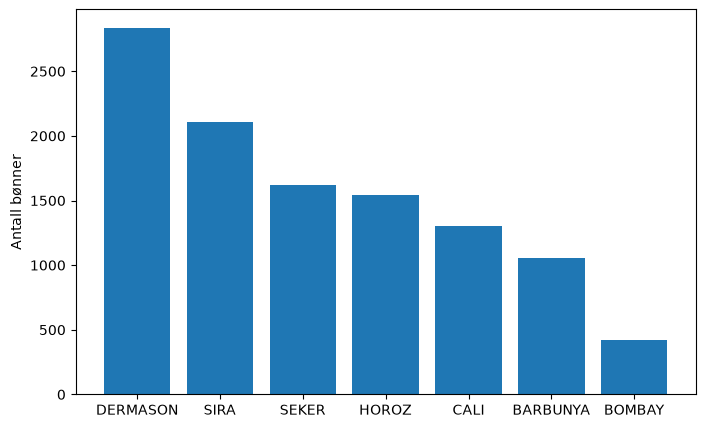

In [7]:
print(y.value_counts())
print("Manglende verdier:", X.isna().sum().sum())

antall = y_train.value_counts()
plt.figure(figsize=(8, 5))
plt.bar(antall.index, antall.values)
plt.ylabel("Antall bønner")
plt.show()

## Scaling

In [9]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)       # Learns mean and spread, and scales
X_test_s = scaler.transform(X_test)             # Uses the same numbers on the test set

print(X_train_s.mean(axis=0).round(2))
print(X_train_s.std(axis=0).round(2))

[ 0. -0. -0. -0. -0. -0. -0. -0.  0.  0.  0.  0. -0.  0. -0. -0.]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


# Plotting

In [12]:
pca = PCA(n_components=16)                       # Says how many axes we want (here we have to try different things and see what works. 2 axes are just easier to plot)
X_train_pca = pca.fit_transform(X_train_s)      # Finds the axes we asked for above

print("Explained variance:", pca.explained_variance_ratio_.round(2))
print("Percentages of data for each axis we include:",(PCA().fit(X_train_s).explained_variance_ratio_.cumsum() * 100).round(1))

Explained variance: [0.55 0.26 0.08 0.05 0.03 0.01 0.01 0.   0.   0.   0.   0.   0.   0.
 0.   0.  ]
Percentages of data for each axis we include: [ 55.5  81.9  90.   95.1  97.8  98.9  99.6  99.9 100.  100.  100.  100.
 100.  100.  100.  100. ]


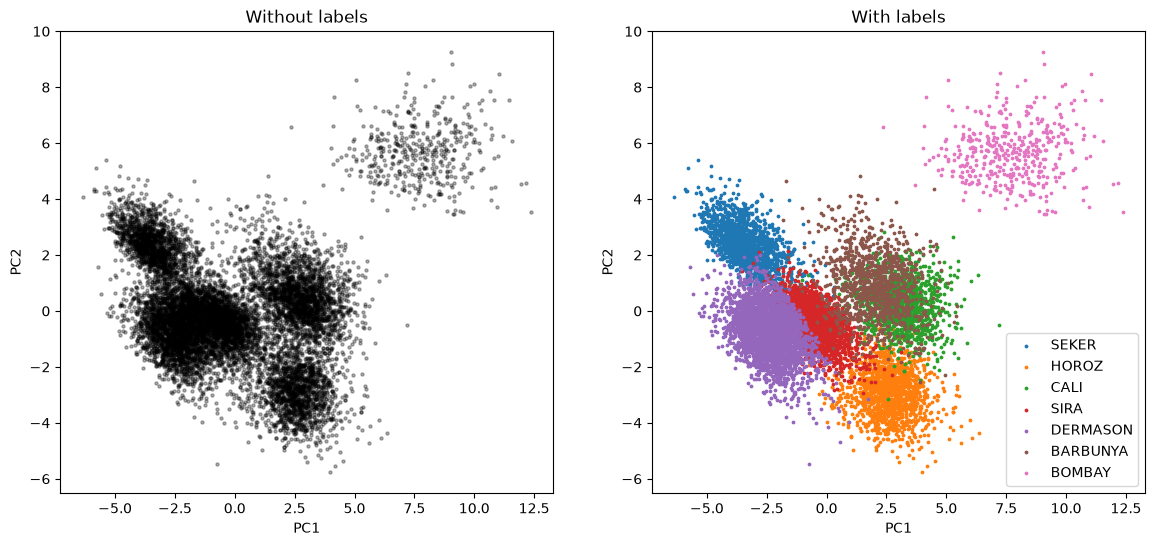

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Left: without labels
ax1.scatter(X_train_pca[:, 0], X_train_pca[:, 1], s=5, color="black", alpha=0.3)
ax1.set_title("Without labels")

# Right: colored by bean type
for i in y_train.unique():
    mask = (y_train == i).values
    ax2.scatter(X_train_pca[mask, 0], X_train_pca[mask, 1], s=3, label=i)
ax2.set_title("With labels")
ax2.legend()

for ax in (ax1, ax2):
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

plt.show()

### Plots showing overlap between the data

Problems with showing the data this way: We plot one bean type at a time, so the overlaps become hard to see.

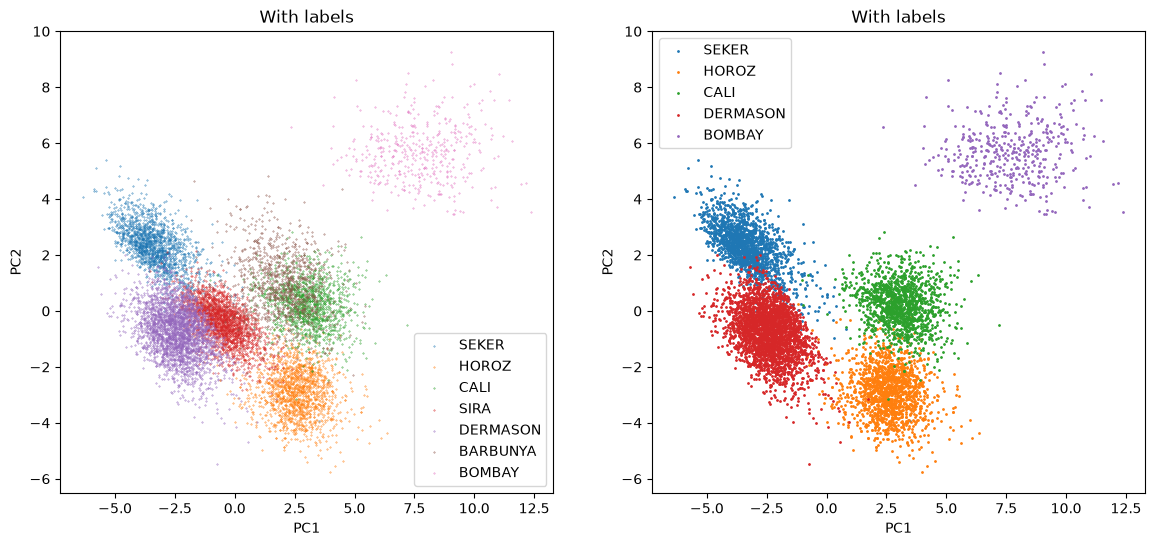

In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

for i in y_train.unique():
    mask = (y_train == i).values
    ax1.scatter(X_train_pca[mask, 0], X_train_pca[mask, 1], s=0.1, label=i)
ax1.set_title("With labels")
ax1.legend()


for i in y_train.unique():
    if i == "SIRA" or i == "BARBUNYA":
        continue
    mask = (y_train == i).values
    ax2.scatter(X_train_pca[mask, 0], X_train_pca[mask, 1], s=1, label=i)
ax2.set_title("With labels")
ax2.legend()

for ax in (ax1, ax2):
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

plt.show()

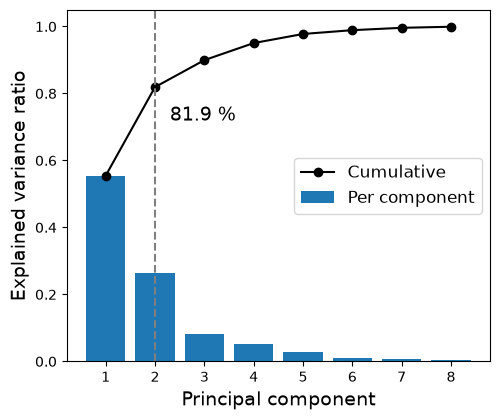

In [25]:


ev = pca.explained_variance_ratio_[:8]          # de 8 første komponentene
cum = np.cumsum(ev)
x = np.arange(1, len(ev) + 1)

fig, ax = plt.subplots(figsize=(5.1, 4.3))
ax.bar(x, ev, label="Per component")
ax.plot(x, cum, marker="o", color="black", label="Cumulative")
ax.axvline(2, linestyle="--", color="grey")
ax.annotate(f"{cum[1]*100:.1f} %", (2, cum[1]), xytext=(2.3, cum[1] - 0.1), fontsize=14)
ax.set_xlabel("Principal component", fontsize=14)
ax.set_ylabel("Explained variance ratio", fontsize=14)
ax.set_xticks(x)
ax.legend(fontsize=12)
fig.tight_layout()
fig.savefig("scree.png", dpi=300)

# K-Mean

In [ ]:
random.seed(42)     # Gives the same starting centers every time, so the result doesn't change. We use this in the kmeans function.


def distance(p, q):         # Calculates the distance between two points in a multidimensional space
    s = 0
    for i in range(len(p)):
        s += (p[i] - q[i])**2
    return math.sqrt(s)


def nearest_center(point, centers): # Finds which group a point belongs to
    best_idx = 0
    min_distance = distance(point, centers[0])
    for i in range(1, len(centers)):
        d = distance(point, centers[i])
        if d < min_distance:
            min_distance = d
            best_idx = i
    return best_idx



# The function was made by Claude, so I went through it carefully to make sure I understood it well
def mean(group):            # Calculates the mean point of a group in a multidimensional space
    d = len(group[0])               # Finds the number of dimensions
    sums = [0] * d                  # Makes a list with one zero for each dimension 
    for point in group:             # Goes through one point at a time
        for i in range(d):          
            sums[i] += point[i]     # Goes through each coordinate and adds the value to the sum for its dimension
    
    n = len(group)                  # Counts and finds the number of points in the given group
    result = []                   
    for s in sums:
        result.append(s / n)        # Makes an empty list and divides each sum by the number of points. (basically a regular mean)
    return result                



def kmeans(points, k):                                      # Takes in all points (nested lists) and the number of clusters we want
    centers = random.sample(points, k)                      # Picks k different points as centers

    while True:
        groups = [[] for _ in range(k)]                     # Makes k empty lists. One for each group.

        for point in points:                                # Goes through all the points and uses nearest_center to find which group the point is closest to
            i = nearest_center(point, centers)
            groups[i].append(point)
        
        new_centers = []                                     
        for i in range(k):                                  # Goes through all the groups
            if len(groups[i]) == 0:                         # Safety check for cases where a group didn't get any points
                new_centers.append(centers[i])
            else:
                new_centers.append(mean(groups[i]))         # Sets the new center as the mean of the group 
        
        if new_centers == centers:                          # If the groups don't move, we call it done
            return centers, groups

        centers = new_centers

## Ilustrating K-Mean results
Note that the plot is the 2D version of the data (after we have applied PCA). K-mean uses all 16 dimensions of the data, and that is why some of the colored dots are closer to other center points than to the one of their own color.

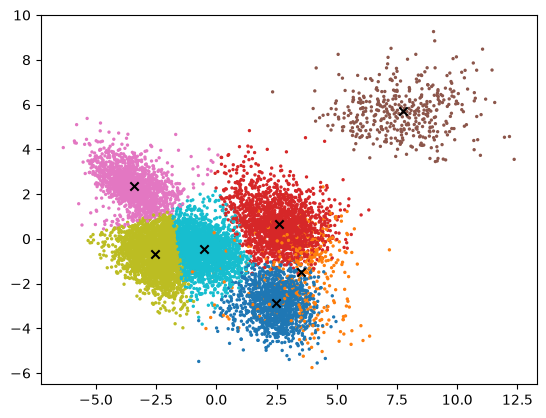

In [26]:
points = X_train_s.tolist()
centers, groups = kmeans(points, 7)

labels = [nearest_center(p, centers) for p in points]
centers_pca = pca.transform(np.array(centers))

plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=labels, s=2, cmap="tab10")
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], c="black", marker="x")
plt.show()

The table below shows how many of each bean type end up in each group (Across (0-6) are the different classes the data has been split into, while the numbers below are how many of the beans ended up in that class). So we can look at the table, see which number is largest under each number (0-6), and use that to say which class that k group represents

In [ ]:
random.seed(42)

centers, groups = kmeans(points, 7)
labels = [nearest_center(p, centers) for p in points]

table = pd.crosstab(y_train.values, labels)
print(table)

purity = table.max() / table.sum()          # Andelen av den største typen i hver cluster (kolonne)
print((purity * 100).round(1))
print(table.idxmax())                       # Hvilken type som er flest i hver cluster. https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.idxmax.html

col_0        0    1     2     3    4     5     6
row_0                                           
BARBUNYA   103    0    11     6   40   897     0
BOMBAY       0  417     0     0    0     1     0
CALI        37    0     0    23    4  1240     0
DERMASON   226    0    84     5  602     1  1919
HOROZ       52    0     0  1411    3    74     2
SEKER       18    0  1409     0  187     2     5
SIRA      1233    0     6    32  800     9    29
col_0
0     73.9
1    100.0
2     93.3
3     95.5
4     48.9
5     55.8
6     98.2
dtype: float64
col_0
0        SIRA
1      BOMBAY
2       SEKER
3       HOROZ
4        SIRA
5        CALI
6    DERMASON
dtype: str


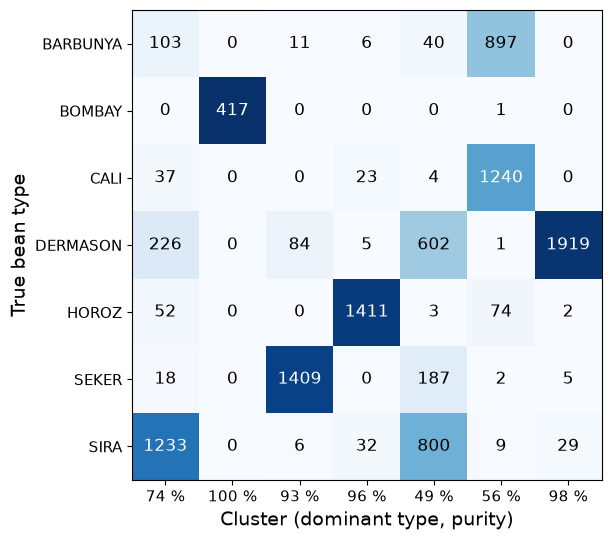

In [44]:
purity = table.max() / table.sum()
dominant = table.idxmax()
col_names = [f"{purity[c]*100:.0f} %" for c in table.columns]

fig, ax = plt.subplots(figsize=(10, 5.5))
share = table / table.sum()                               # Hver rute delt på summen av kolonnen

ax.imshow(share.values, cmap="Blues", vmin=0, vmax=1)    # Farge etter andel, fra 0 til 1

for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        color = "white" if share.values[i, j] > 0.5 else "black"
        ax.text(j, i, table.values[i, j], ha="center", va="center", fontsize=12, color=color)

ax.set_xticks(range(len(col_names)), col_names, fontsize=11)
ax.set_yticks(range(len(table.index)), table.index, fontsize=11)
ax.set_xlabel("Cluster (dominant type, purity)", fontsize=14)
ax.set_ylabel("True bean type", fontsize=14)
fig.tight_layout()
fig.savefig("crosstab.png", dpi=300)

## Elbow point

1 174208
2 133065
3 75690
4 61095
5 49440
6 44323
7 42525
8 41174
9 34239
10 32956


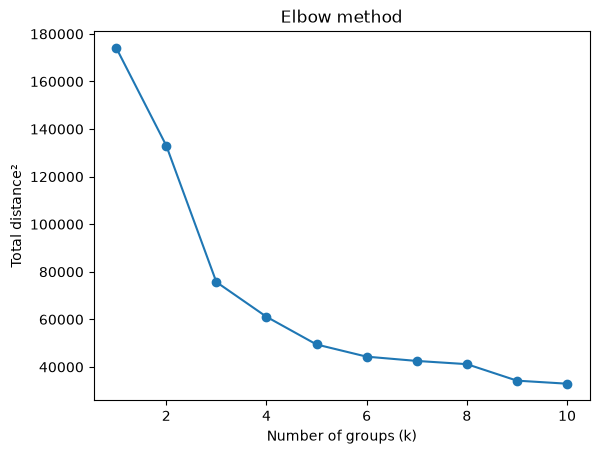

In [20]:
def total_distance(centers, groups):    # The sum of (distance to own center)² for all points
    s = 0
    for i in range(len(centers)):
        for point in groups[i]:
            s += distance(point, centers[i])**2
    return s


k_values = range(1, 11)
results = []

for k in k_values:
    random.seed(42)
    centers, groups = kmeans(points, k)
    results.append(total_distance(centers, groups))
    print(k, round(results[-1]))       # Shows the progress along the way

plt.plot(k_values, results, marker="o")
plt.xlabel("Number of groups (k)")
plt.ylabel("Total distance²")
plt.title("Elbow method")
plt.show()

### Running K-means several times
K-means depends on which points are picked as starting centers. A bad start can make the algorithm get stuck in a poor solution (a local minimum), so a single run per k can give a misleading value. This can make the elbow curve uneven, and in the worst case the total distance can even go up when k increases, which should not happen with a good solution.

To make the curve more reliable, we run K-means 5 times for each k, each time with new random starting centers, and keep the run with the lowest total distance squared. The seed is set once before the loop, so the whole experiment gives the same result every time, while each attempt still gets different starting centers.

More attempts give a more reliable result, but take longer to run, since our implementation is written in pure Python. 5 attempts is a compromise between the two.

1 174208
2 103909
3 75690
4 61095
5 49440
6 43875
7 38850
8 36166
9 35653
10 31651


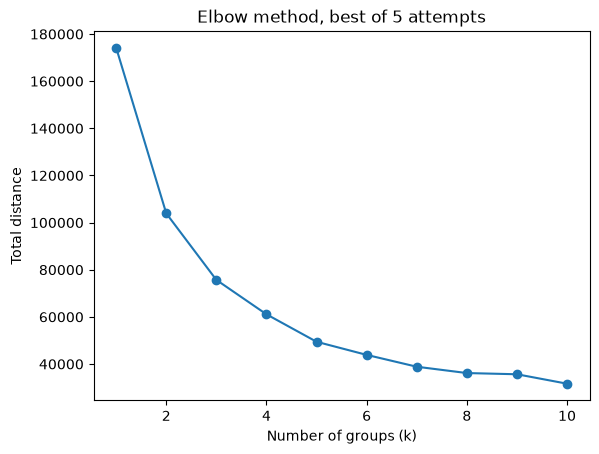

In [21]:
def kmeans_best(points, k, attempts):           # Runs k-means several times and keeps the best result
    best_distance = None

    for _ in range(attempts):
        centers, groups = kmeans(points, k)     # New random starting centers each time
        d = total_distance(centers, groups)

        if best_distance is None or d < best_distance:
            best_distance = d
            best_centers = centers
            best_groups = groups

    return best_centers, best_groups, best_distance

random.seed(42)
k_values = range(1, 11)
results = []

for k in k_values:
    centers, groups, d = kmeans_best(points, k, attempts=5)
    results.append(d)
    print(k, round(d))

plt.plot(k_values, results, marker="o")
plt.xlabel("Number of groups (k)")
plt.ylabel("Total distance")
plt.title("Elbow method, best of 5 attempts")
plt.show()